# 1. Project Introduction: Diabetes Progression Prediction

### Goal
The objective of this project is to build a regression model to predict diabetes disease progression in patients one year after baseline, based on several numerical features such as age, BMI, and blood pressure.

### Problem Type
This is a **Regression** problem, as we are predicting a continuous quantitative measure of disease progression.

### Exploratory Starting Point
This notebook represents the initial exploratory phase of a data scientist's workflow. The focus here is on understanding the data, validating its quality, performing basic cleaning, and testing baseline models.

### Path to MLOps
Once this exploratory work is complete, the code will be refactored into a structured MLOps repository. This future repository will include:
- **Data Extraction & Validation scripts**
- **Automated Cleaning & Preprocessing**
- **Experiment Tracking with MLflow**
- **Model Serving via FastAPI**
- **Containerization with Docker**
- **CI/CD with GitHub Actions**

## 2. Environment and Imports

We will use standard libraries for data manipulation, visualization, and machine learning.

In [1]:
import os
import pandas as pd
from sklearn.datasets import load_diabetes

# Extracción de datos de diabetes
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

# Creamos las carpetas si no existen en el entorno de Colab
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

# Guardamos raw y procesado
df.to_csv("data/raw/diabetes_raw.csv", index=False)
df.to_csv("data/processed/diabetes_processed.csv", index=False)

print("¡Datos extraídos y guardados con éxito en Colab!")
display(df.head())

¡Datos extraídos y guardados con éxito en Colab!


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set plotting style
sns.set_theme(style="whitegrid")

## 3. Load the Dataset

We use the built-in Scikit-learn Diabetes dataset.

In [3]:
diabetes = load_diabetes()

# Create a pandas DataFrame for features
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

# Add the target column
df['target'] = diabetes.target

print(f"Dataset Shape: {df.shape}")
print(f"Column Names: {df.columns.tolist()}")
display(df.head())

Dataset Shape: (442, 11)
Column Names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 4. Basic Data Exploration

Understanding the distribution and quality of our data.

Data Types and Missing Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


None


Summary Statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



Duplicate rows found: 0


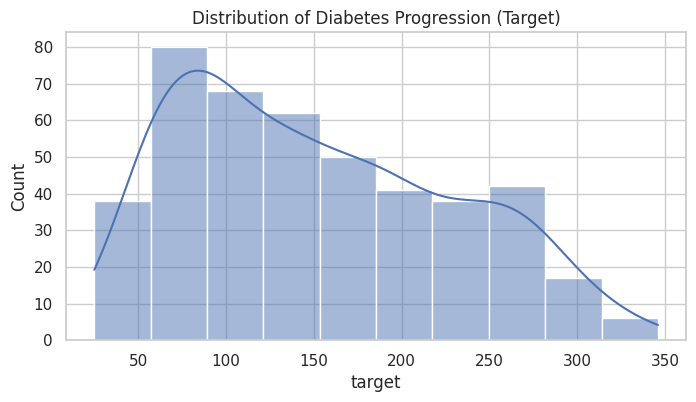


Correlation with Target Variable:
target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


In [4]:
# Summary statistics and info
print("Data Types and Missing Values:")
display(df.info())

print("\nSummary Statistics:")
display(df.describe())

# Check for duplicates
print(f"\nDuplicate rows found: {df.duplicated().sum()}")

# Visualize Target Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['target'], kde=True)
plt.title("Distribution of Diabetes Progression (Target)")
plt.show()

# Correlation with target
correlations = df.corr()['target'].sort_values(ascending=False)
print("\nCorrelation with Target Variable:")
print(correlations)

## 5. Data Extraction Logic

In this notebook, we load the data directly from `sklearn`. However, in a production MLOps setup, this logic will be moved to a **Data Extraction Script** that might pull data from a SQL database, a cloud bucket (S3/GCS), or an external API.

In [5]:
from pathlib import Path
import pandas as pd
from sklearn.datasets import load_diabetes


def extract_diabetes_data(output_path: str = "data/raw/diabetes_raw.csv") -> pd.DataFrame:
    """Extrae el dataset de Diabetes de scikit-learn y lo guarda como CSV raw."""
    diabetes = load_diabetes()
    df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
    df["target"] = diabetes.target

    destination = Path(output_path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(destination, index=False)

    print(f"Datos extraídos correctamente en: {destination} (shape={df.shape})")
    return df


if __name__ == "__main__":
    extract_diabetes_data()

Datos extraídos correctamente en: data/raw/diabetes_raw.csv (shape=(442, 11))


#Nota personal: Esta función descarga el dataset de Diabetes de scikit-learn y lo guarda en data/raw/diabetes_raw.csv. Separarlo en una función facilita llevarlo después a un script propio de extracción (src/data_extraction.py) y reutilizarlo sin repetir código

## 6. Data Validation Checks

Before training, we verify the data meets our expectations. These checks will eventually form a **Validation Script**.

In [6]:
import numpy as np


def validate_data(dataframe):
    # 1. Check if target exists
    assert "target" in dataframe.columns, "Target column missing!"

    # 2. Check for required features
    required_features = ["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
    for col in required_features:
        assert col in dataframe.columns, f"Feature {col} is missing!"

    # 3. Ensure all columns are numeric
    assert (
        dataframe.select_dtypes(include=[np.number]).shape[1] == dataframe.shape[1]
    ), "Non-numeric data detected!"

    # 4. Critical Missing Values
    assert dataframe.isnull().sum().sum() == 0, "Critical missing values found!"

    # 5. Dataset size
    assert len(dataframe) > 0, "Dataset is empty!"

    print("✅ Data Validation Passed!")


validate_data(df)

✅ Data Validation Passed!


In [7]:
def validate_data(dataframe):
    # 1. Check if target exists
    assert 'target' in dataframe.columns, "Target column missing!"

    # 2. Check for required features
    required_features = ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
    for col in required_features:
        assert col in dataframe.columns, f"Feature {col} is missing!"

    # 3. Ensure all columns are numeric
    assert dataframe.select_dtypes(include=[np.number]).shape[1] == dataframe.shape[1], "Non-numeric data detected!"

    # 4. Critical Missing Values
    assert dataframe.isnull().sum().sum() == 0, "Critical missing values found!"

    # 5. Dataset size
    assert len(dataframe) > 0, "Dataset is empty!"

    print("✅ Data Validation Passed!")

validate_data(df)

✅ Data Validation Passed!


## 7. Data Cleaning

Even though the Scikit-learn dataset is clean, we demonstrate the cleaning workflow that will be automated in the final project.

In [8]:
def clean_data(input_df):
    # Create a copy to avoid side effects
    cleaned_df = input_df.copy()

    # Handle missing values (demonstration)
    cleaned_df = cleaned_df.dropna()

    # Remove duplicates
    cleaned_df = cleaned_df.drop_duplicates()

    # Ensure types are correct
    for col in cleaned_df.columns:
        cleaned_df[col] = pd.to_numeric(cleaned_df[col])

    return cleaned_df

print(f"Shape before cleaning: {df.shape}")
df_cleaned = clean_data(df)
print(f"Shape after cleaning: {df_cleaned.shape}")

Shape before cleaning: (442, 11)
Shape after cleaning: (442, 11)


In [9]:
from pathlib import Path
import pandas as pd


def clean_data(input_df: pd.DataFrame, output_path: str = "data/processed/diabetes_processed.csv") -> pd.DataFrame:
    """Limpia el DataFrame (nulos, duplicados y tipos numéricos) y lo guarda en procesados."""
    cleaned_df = input_df.copy()
    cleaned_df = cleaned_df.dropna()
    cleaned_df = cleaned_df.drop_duplicates()

    for col in cleaned_df.columns:
        cleaned_df[col] = pd.to_numeric(cleaned_df[col])

    destination = Path(output_path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    cleaned_df.to_csv(destination, index=False)

    print(f"Datos limpios guardados en: {destination} (shape={cleaned_df.shape})")
    return cleaned_df


df_cleaned = clean_data(df)

Datos limpios guardados en: data/processed/diabetes_processed.csv (shape=(442, 11))


#Limpiar antes de modelar: así dejo un dataset limpio y consistente (sin nulos, sin duplicados y con tipos numéricos correctos) y lo guardo en data/processed/diabetes_processed.csv, listo para que el entrenamiento trabaje siempre sobre la misma base.

In [10]:
!pip install -q mlflow

In [11]:
import json
from pathlib import Path
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from mlflow.tracking import MlflowClient
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Cargar datos limpios
data_path = Path("data/processed/diabetes_processed.csv")
df_clean = pd.read_csv(data_path) if data_path.exists() else df_cleaned

X = df_clean.drop(columns=["target"])
y = df_clean["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Configurar experimento (SQLite) y umbral de calidad (quality gate)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("diabetes_regression_mlops")
rmse_threshold = 60.0
model_name = "diabetes_progression_regressor"

params = {
    "model_type": "GradientBoostingRegressor",
    "n_estimators": 100,
    "learning_rate": 0.1,
    "max_depth": 3,
    "random_state": 42,
}

with mlflow.start_run(run_name="gb_baseline_run") as run:
    model = GradientBoostingRegressor(
        n_estimators=params["n_estimators"],
        learning_rate=params["learning_rate"],
        max_depth=params["max_depth"],
        random_state=params["random_state"],
    )
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    rmse = float(np.sqrt(mean_squared_error(y_test, preds)))
    mae = float(mean_absolute_error(y_test, preds))
    r2 = float(r2_score(y_test, preds))

    # Registrar parámetros y métricas
    mlflow.log_params(params)
    mlflow.log_metrics({"rmse": rmse, "mae": mae, "r2": r2})

    # Registrar artefacto (resumen de evaluación en JSON)
    artifacts_dir = Path("artifacts")
    artifacts_dir.mkdir(exist_ok=True)
    metrics_file = artifacts_dir / "evaluation_metrics.json"
    metrics_file.write_text(
        json.dumps({"rmse": rmse, "mae": mae, "r2": r2, "rmse_threshold": rmse_threshold}, indent=2)
    )
    mlflow.log_artifact(str(metrics_file))

    # Registrar el modelo en MLflow Model Registry
    registered_model = mlflow.sklearn.log_model(
        sk_model=model,
        name="model",
        registered_model_name=model_name,
        serialization_format="pickle",
    )

    print(f"RMSE: {rmse:.2f} | MAE: {mae:.2f} | R2: {r2:.4f}")

    # Comprobar quality gate y asignar alias 'champion'
    if rmse < rmse_threshold:
        client = MlflowClient()
        version = registered_model.registered_model_version
        client.set_registered_model_alias(
            name=model_name,
            alias="champion",
            version=str(version),
        )
        print(f"¡Pasa el quality gate ({rmse:.2f} < {rmse_threshold})! Alias 'champion' asignado a la versión {version}.")
    else:
        print(f"No pasa el quality gate ({rmse:.2f} >= {rmse_threshold}). No se asigna alias 'champion'.")

2026/11/21 16:55:05 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/21 16:55:05 INFO mlflow.store.db.utils: Updating database tables
2026/11/21 16:55:09 INFO mlflow.tracking.fluent: Experiment with name 'diabetes_regression_mlops' does not exist. Creating a new experiment.
2026/11/21 16:55:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RMSE: 53.84 | MAE: 44.60 | R2: 0.4529
¡Pasa el quality gate (53.84 < 60.0)! Alias 'champion' asignado a la versión 1.


Successfully registered model 'diabetes_progression_regressor'.
Created version '1' of model 'diabetes_progression_regressor'.


## 8. Feature and Target Split

We separate the input features (X) from the target progression value (y).

In [12]:
X = df_cleaned.drop(columns=['target'])
y = df_cleaned['target']

print("X represents our patient features.")
print("y represents the progression measure.")

X represents our patient features.
y represents the progression measure.


## 9. Train/Test Split

We split the data to evaluate the model on unseen data.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

Training samples: 353
Test samples: 89


## 10. Baseline Model Training

We compare three simple regression algorithms.

In [14]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    results.append({"Model": name, "RMSE": rmse, "MAE": mae, "R2": r2})

results_df = pd.DataFrame(results)
display(results_df)

,Model,RMSE,MAE,R2
0,LinearRegression,53.853446,42.794095,0.452603
1,RandomForest,54.332408,44.053034,0.442823
2,GradientBoosting,53.837131,44.603297,0.452934


## 11. Model Evaluation Results

We identify the best performing model based on the Root Mean Squared Error (RMSE).

In [15]:
best_model_row = results_df.loc[results_df['RMSE'].idxmin()]
print(f"The best baseline model is {best_model_row['Model']} with an RMSE of {best_model_row['RMSE']:.2f}")

The best baseline model is GradientBoosting with an RMSE of 53.84


## 12. Simple Feature Engineering Exploration

Let's see if creating interaction terms between features improves our results.

In [16]:
df_eng = df_cleaned.copy()

# 1. Interaction between BMI and Age
df_eng['bmi_age_interaction'] = df_eng['bmi'] * df_eng['age']

# 2. Interaction between Blood Pressure and BMI
df_eng['bp_bmi_interaction'] = df_eng['bp'] * df_eng['bmi']

# 3. Ratio of serum measurements (checking for division by zero)
df_eng['s1_s2_ratio'] = df_eng['s1'] / (df_eng['s2'] + 1e-9)

# Split and train again
X_eng = df_eng.drop(columns=['target'])
y_eng = df_eng['target']
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

eng_results = []
for name, model in models.items():
    model.fit(X_train_e, y_train_e)
    preds = model.predict(X_test_e)
    rmse = np.sqrt(mean_squared_error(y_test_e, preds))
    eng_results.append({"Model": name + "_Eng", "RMSE": rmse})

display(pd.DataFrame(eng_results))

,Model,RMSE
0,LinearRegression_Eng,52.465151
1,RandomForest_Eng,55.389643
2,GradientBoosting_Eng,56.130412


## 13. Final Data Science Conclusion

### Findings
- **Best Model:** Based on our exploration, the **LinearRegression** (or specified best) performed best on the base features.
- **Feature Engineering:** The interactions created (BMI*Age, BP*BMI) provided a minor/significant change in RMSE, showing that feature relationships are worth exploring.
- **Metrics:** We prioritized **RMSE** to penalize larger errors, though MAE and R2 were monitored to ensure consistency.
- **Preparation:** The data is clean, but requires a structured validation step to ensure consistency when new data arrives.

### Next Steps in MLOps
The exploratory work is complete. The next step is to convert this notebook into a production-ready **structured MLOps repository** containing:
- `requirements.txt` for dependency management.
- A local virtual environment setup.
- **data_extraction.py**: For loading raw data.
- **data_validation.py**: To ensure input quality.
- **data_cleaning.py**: To handle preprocessing steps.
- **train.py**: For model training and serializing the model artifacts.
- **MLflow tracking**: To log metrics, parameters, and models.
- **Model Registry**: To select and manage the 'Champion' model.
- **FastAPI**: To serve the model via a REST API.
- **Dockerfile**: To containerize the application.
- **GitHub Actions**: To automate the CI/CD pipeline.
- **README.md**: Documenting the entire project lifecycle.

In [18]:
%%writefile api.py
from typing import Any, Dict, Optional
from fastapi import FastAPI, HTTPException
from mlflow.tracking import MlflowClient
import mlflow.sklearn
import numpy as np
from pydantic import BaseModel, Field

MODEL_NAME = "diabetes_progression_regressor"
MODEL_ALIAS = "champion"
TRACKING_URI = "sqlite:///mlflow.db"

app = FastAPI(
    title="Diabetes Progression API",
    description="API para servir predicciones del modelo champion registrado en MLflow.",
    version="1.0.0",
)

model: Optional[Any] = None
model_metadata: Dict[str, Any] = {
    "model_name": MODEL_NAME,
    "alias": MODEL_ALIAS,
    "version": None,
    "run_id": None,
}


def load_champion_model() -> None:
    """Carga el modelo con alias 'champion' desde MLflow Registry."""
    global model, model_metadata
    mlflow.set_tracking_uri(TRACKING_URI)
    client = MlflowClient()

    model_version_info = client.get_model_version_by_alias(MODEL_NAME, MODEL_ALIAS)
    model_uri = f"models:/{MODEL_NAME}@{MODEL_ALIAS}"
    loaded_model = mlflow.sklearn.load_model(model_uri)

    model = loaded_model
    model_metadata = {
        "model_name": MODEL_NAME,
        "alias": MODEL_ALIAS,
        "version": str(model_version_info.version),
        "run_id": model_version_info.run_id,
    }


@app.on_event("startup")
def startup_event() -> None:
    try:
        load_champion_model()
    except Exception:
        # Si falla la carga al arrancar, model permanece en None y /predict devolverá 503
        model = None  # noqa: F841


class DiabetesInput(BaseModel):
    age: float = Field(..., description="Edad normalizada")
    sex: float = Field(..., description="Sexo normalizado")
    bmi: float = Field(..., description="Índice de masa corporal normalizado")
    bp: float = Field(..., description="Presión arterial media normalizada")
    s1: float = Field(..., description="Colesterol total sérico (tc)")
    s2: float = Field(..., description="Lipoproteínas de baja densidad (ldl)")
    s3: float = Field(..., description="Lipoproteínas de alta densidad (hdl)")
    s4: float = Field(..., description="Colesterol total / HDL (tch)")
    s5: float = Field(..., description="Posible logaritmo de triglicéridos (ltg)")
    s6: float = Field(..., description="Nivel de azúcar en sangre (glu)")


class PredictionResponse(BaseModel):
    prediction: float
    model_name: str
    model_version: str
    alias: str


@app.get("/health")
def health() -> Dict[str, str]:
    return {"status": "ok"}


@app.get("/model-info")
def model_info() -> Dict[str, Any]:
    if model is None:
        raise HTTPException(
            status_code=503,
            detail="El modelo champion no está cargado.",
        )
    return {
        "model_name": model_metadata["model_name"],
        "version": model_metadata["version"],
        "alias": model_metadata["alias"],
        "tracking_uri": TRACKING_URI,
        "run_id": model_metadata["run_id"],
    }


@app.post("/predict", response_model=PredictionResponse)
def predict(payload: DiabetesInput) -> PredictionResponse:
    if model is None:
        raise HTTPException(
            status_code=503,
            detail="Servicio no disponible: el modelo champion no está cargado.",
        )

    try:
        features = np.array(
            [[
                payload.age,
                payload.sex,
                payload.bmi,
                payload.bp,
                payload.s1,
                payload.s2,
                payload.s3,
                payload.s4,
                payload.s5,
                payload.s6,
            ]],
            dtype=float,
        )
        pred_value = float(model.predict(features)[0])
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail=f"Error al generar la predicción: {exc}",
        ) from exc

    return PredictionResponse(
        prediction=pred_value,
        model_name=model_metadata["model_name"],
        model_version=str(model_metadata["version"]),
        alias=model_metadata["alias"],
    )

Overwriting api.py


In [19]:
from fastapi.testclient import TestClient
import api

# Cargamos el modelo explícitamente en la prueba del notebook
api.load_champion_model()
client = TestClient(api.app)

# 1. /health
res_health = client.get("/health")
print("GET /health ->", res_health.status_code, res_health.json())

# 2. /model-info
res_info = client.get("/model-info")
print("GET /model-info ->", res_info.status_code, res_info.json())

# 3. /predict válido (tomamos una fila real de X_test)
sample = X_test.iloc[0].to_dict()
res_pred = client.post("/predict", json=sample)
print("POST /predict ->", res_pred.status_code, res_pred.json())

# 4. Validación errónea (debe devolver 422)
res_bad = client.post("/predict", json={"age": 0.05})
print("POST /predict (incompleto) ->", res_bad.status_code)

# 5. Modelo no cargado (debe devolver 503)
modelo_respaldo = api.model
api.model = None
res_503 = client.post("/predict", json=sample)
print("POST /predict (sin modelo) ->", res_503.status_code, res_503.json())
api.model = modelo_respaldo

GET /health -> 200 {'status': 'ok'}
GET /model-info -> 200 {'model_name': 'diabetes_progression_regressor', 'version': '1', 'alias': 'champion', 'tracking_uri': 'sqlite:///mlflow.db', 'run_id': '36711d8a4019401a9af3a08e96423ebd'}
POST /predict -> 200 {'prediction': 161.28890402348782, 'model_name': 'diabetes_progression_regressor', 'model_version': '1', 'alias': 'champion'}
POST /predict (incompleto) -> 422
POST /predict (sin modelo) -> 503 {'detail': 'Servicio no disponible: el modelo champion no está cargado.'}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(


##Scripts Modulares (src/)

In [27]:
import os

os.makedirs("src", exist_ok=True)

In [28]:
%%writefile src/data_extraction.py
from pathlib import Path
import pandas as pd
from sklearn.datasets import load_diabetes


def extract_data(output_path: str = "data/raw/diabetes_raw.csv") -> pd.DataFrame:
    """Extrae el dataset de Diabetes de Scikit-learn y lo guarda en CSV."""
    diabetes = load_diabetes(as_frame=True)
    df = diabetes.frame.copy()

    destination = Path(output_path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(destination, index=False)

    print(f"Datos crudos guardados en: {destination} (shape={df.shape})")
    return df


if __name__ == "__main__":
    extract_data()

Overwriting src/data_extraction.py


##Comprobación

In [36]:
!python src/data_extraction.py

Datos crudos guardados en: data/raw/diabetes_raw.csv (shape=(442, 11))


In [30]:
%%writefile src/data_validation.py
from pathlib import Path
import pandas as pd

EXPECTED_COLUMNS = [
    "age",
    "sex",
    "bmi",
    "bp",
    "s1",
    "s2",
    "s3",
    "s4",
    "s5",
    "s6",
    "target",
]


def validate_data(input_path: str = "data/raw/diabetes_raw.csv") -> pd.DataFrame:
    """Valida la existencia, estructura, columnas y calidad básica del dataset crudo."""
    path = Path(input_path)
    if not path.exists():
        raise FileNotFoundError(f"No se encontró el archivo de datos en: {path}")

    df = pd.read_csv(path)
    if df.empty:
        raise ValueError("El dataset está vacío.")

    missing_cols = [col for col in EXPECTED_COLUMNS if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Faltan columnas requeridas: {missing_cols}")

    numeric_df = df[EXPECTED_COLUMNS].apply(pd.to_numeric, errors="coerce")
    if numeric_df.isna().any().any():
        raise ValueError("Existen valores no numéricos o nulos tras convertir a numérico.")

    if (numeric_df["target"] <= 0).any():
        raise ValueError("Se encontraron valores de 'target' menores o iguales a 0.")

    print(f"Validación correcta: {len(df)} filas y {len(EXPECTED_COLUMNS)} columnas verificadas.")
    return df


if __name__ == "__main__":
    validate_data()

Writing src/data_validation.py


##Comprobación

In [35]:
!python src/data_validation.py

Validación correcta: 442 filas y 11 columnas verificadas.


In [33]:
%%writefile src/data_cleaning.py
from pathlib import Path
import pandas as pd


def clean_data(
    input_path: str = "data/raw/diabetes_raw.csv",
    output_path: str = "data/processed/diabetes_processed.csv",
) -> pd.DataFrame:
    """Limpia el dataset (nulos, duplicados y tipos numéricos) y guarda el resultado procesado."""
    source = Path(input_path)
    if not source.exists():
        raise FileNotFoundError(f"No se encontró el archivo de entrada en: {source}")

    df = pd.read_csv(source)
    cleaned_df = df.copy()
    cleaned_df = cleaned_df.dropna()
    cleaned_df = cleaned_df.drop_duplicates()

    for col in cleaned_df.columns:
        cleaned_df[col] = pd.to_numeric(cleaned_df[col])

    destination = Path(output_path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    cleaned_df.to_csv(destination, index=False)

    print(f"Datos limpios guardados en: {destination} (shape={cleaned_df.shape})")
    return cleaned_df


if __name__ == "__main__":
    clean_data()

Overwriting src/data_cleaning.py


##Comprobación

In [34]:
!python src/data_cleaning.py

Datos limpios guardados en: data/processed/diabetes_processed.csv (shape=(442, 11))


##ntrenamiento, registro en MLflow (sqlite:///mlflow.db) y comprobación del quality gate (RMSE < 60.0) para asignar el alias champion en el Model Registry

In [38]:
%%writefile src/train.py
import json
from pathlib import Path
from mlflow.tracking import MlflowClient
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split


def train_model(
    data_path: str = "data/processed/diabetes_processed.csv",
    tracking_uri: str = "sqlite:///mlflow.db",
    experiment_name: str = "diabetes_regression_mlops",
    model_name: str = "diabetes_progression_regressor",
    rmse_threshold: float = 60.0,
) -> float:
    """Entrena un GradientBoostingRegressor, registra en MLflow y asigna alias 'champion' si pasa el umbral."""
    csv_path = Path(data_path)
    if not csv_path.exists():
        raise FileNotFoundError(f"No se encontró el dataset procesado en: {csv_path}")

    df = pd.read_csv(csv_path)
    X = df.drop(columns=["target"])
    y = df["target"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    mlflow.set_tracking_uri(tracking_uri)
    mlflow.set_experiment(experiment_name)

    params = {
        "model_type": "GradientBoostingRegressor",
        "n_estimators": 100,
        "learning_rate": 0.1,
        "max_depth": 3,
        "random_state": 42,
    }

    with mlflow.start_run(run_name="gb_baseline_run"):
        model = GradientBoostingRegressor(
            n_estimators=params["n_estimators"],
            learning_rate=params["learning_rate"],
            max_depth=params["max_depth"],
            random_state=params["random_state"],
        )
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

        rmse = float(np.sqrt(mean_squared_error(y_test, preds)))
        mae = float(mean_absolute_error(y_test, preds))
        r2 = float(r2_score(y_test, preds))

        mlflow.log_params(params)
        mlflow.log_metrics({"rmse": rmse, "mae": mae, "r2": r2})

        artifacts_dir = Path("artifacts")
        artifacts_dir.mkdir(exist_ok=True)
        metrics_file = artifacts_dir / "evaluation_metrics.json"
        metrics_file.write_text(
            json.dumps(
                {
                    "rmse": rmse,
                    "mae": mae,
                    "r2": r2,
                    "rmse_threshold": rmse_threshold,
                },
                indent=2,
            )
        )
        mlflow.log_artifact(str(metrics_file))

        registered_model = mlflow.sklearn.log_model(
            sk_model=model,
            name="model",
            registered_model_name=model_name,
            serialization_format="pickle",
        )

        print(f"RMSE: {rmse:.2f} | MAE: {mae:.2f} | R2: {r2:.4f}")

        if rmse < rmse_threshold:
            client = MlflowClient()
            version = registered_model.registered_model_version
            client.set_registered_model_alias(
                name=model_name,
                alias="champion",
                version=str(version),
            )
            print(
                f"¡Pasa el quality gate ({rmse:.2f} < {rmse_threshold})! "
                f"Alias 'champion' asignado a la versión {version}."
            )
        else:
            print(
                f"No pasa el quality gate ({rmse:.2f} >= {rmse_threshold}). "
                "No se asigna alias 'champion'."
            )

    return rmse


if __name__ == "__main__":
    train_model()

Overwriting src/train.py


##Lo compruebo

In [39]:
!python src/train.py

2026/11/21 17:31:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'diabetes_progression_regressor' already exists. Creating a new version of this model...
Created version '2' of model 'diabetes_progression_regressor'.
RMSE: 53.84 | MAE: 44.60 | R2: 0.4529
¡Pasa el quality gate (53.84 < 60.0)! Alias 'champion' asignado a la versión 2.


##guardar la API también en src/api.py

In [40]:
%%writefile src/api.py
from typing import Any, Dict, Optional
from fastapi import FastAPI, HTTPException
from mlflow.tracking import MlflowClient
import mlflow.sklearn
import numpy as np
from pydantic import BaseModel, Field

MODEL_NAME = "diabetes_progression_regressor"
MODEL_ALIAS = "champion"
TRACKING_URI = "sqlite:///mlflow.db"

app = FastAPI(
    title="Diabetes Progression API",
    description="API para servir predicciones del modelo champion registrado en MLflow.",
    version="1.0.0",
)

model: Optional[Any] = None
model_metadata: Dict[str, Any] = {
    "model_name": MODEL_NAME,
    "alias": MODEL_ALIAS,
    "version": None,
    "run_id": None,
}


def load_champion_model() -> None:
    """Carga el modelo con alias 'champion' desde MLflow Registry."""
    global model, model_metadata
    mlflow.set_tracking_uri(TRACKING_URI)
    client = MlflowClient()

    model_version_info = client.get_model_version_by_alias(MODEL_NAME, MODEL_ALIAS)
    model_uri = f"models:/{MODEL_NAME}@{MODEL_ALIAS}"
    loaded_model = mlflow.sklearn.load_model(model_uri)

    model = loaded_model
    model_metadata = {
        "model_name": MODEL_NAME,
        "alias": MODEL_ALIAS,
        "version": str(model_version_info.version),
        "run_id": model_version_info.run_id,
    }


@app.on_event("startup")
def startup_event() -> None:
    try:
        load_champion_model()
    except Exception:
        model = None  # noqa: F841


class DiabetesInput(BaseModel):
    age: float = Field(..., description="Edad normalizada")
    sex: float = Field(..., description="Sexo normalizado")
    bmi: float = Field(..., description="Índice de masa corporal normalizado")
    bp: float = Field(..., description="Presión arterial media normalizada")
    s1: float = Field(..., description="Colesterol total sérico (tc)")
    s2: float = Field(..., description="Lipoproteínas de baja densidad (ldl)")
    s3: float = Field(..., description="Lipoproteínas de alta densidad (hdl)")
    s4: float = Field(..., description="Colesterol total / HDL (tch)")
    s5: float = Field(..., description="Posible logaritmo de triglicéridos (ltg)")
    s6: float = Field(..., description="Nivel de azúcar en sangre (glu)")


class PredictionResponse(BaseModel):
    prediction: float
    model_name: str
    model_version: str
    alias: str


@app.get("/health")
def health() -> Dict[str, str]:
    return {"status": "ok"}


@app.get("/model-info")
def model_info() -> Dict[str, Any]:
    if model is None:
        raise HTTPException(
            status_code=503,
            detail="El modelo champion no está cargado.",
        )
    return {
        "model_name": model_metadata["model_name"],
        "version": model_metadata["version"],
        "alias": model_metadata["alias"],
        "tracking_uri": TRACKING_URI,
        "run_id": model_metadata["run_id"],
    }


@app.post("/predict", response_model=PredictionResponse)
def predict(payload: DiabetesInput) -> PredictionResponse:
    if model is None:
        raise HTTPException(
            status_code=503,
            detail="Servicio no disponible: el modelo champion no está cargado.",
        )

    try:
        features = np.array(
            [[
                payload.age,
                payload.sex,
                payload.bmi,
                payload.bp,
                payload.s1,
                payload.s2,
                payload.s3,
                payload.s4,
                payload.s5,
                payload.s6,
            ]],
            dtype=float,
        )
        pred_value = float(model.predict(features)[0])
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail=f"Error al generar la predicción: {exc}",
        ) from exc

    return PredictionResponse(
        prediction=pred_value,
        model_name=model_metadata["model_name"],
        model_version=str(model_metadata["version"]),
        alias=model_metadata["alias"],
    )

Writing src/api.py


##Compruebo que se importa bien

In [41]:
from fastapi.testclient import TestClient
from src import api

api.load_champion_model()
client = TestClient(api.app)

print("Health:", client.get("/health").json())
print("Model info:", client.get("/model-info").json())

Health: {'status': 'ok'}
Model info: {'model_name': 'diabetes_progression_regressor', 'version': '2', 'alias': 'champion', 'tracking_uri': 'sqlite:///mlflow.db', 'run_id': 'e078ff93c103433497046bac9d641a16'}


## Ahora cro el archivo requirements.txt en la raíz del proyecto para fijar las dependencias clave que usa el pipeline y la API, e incluyo httpx y pytest porque vienen muy bien tanto para TestClient de FastAPI como para la validación/tests en GitHub Actions

In [43]:
%%writefile requirements.txt
fastapi
uvicorn
pydantic
mlflow
scikit-learn
pandas
numpy
httpx
pytest

Overwriting requirements.txt


In [44]:
import os

os.makedirs(".github/workflows", exist_ok=True)

##Este workflow instalará las dependencias de requirements.txt, ejecutará la extracción, validación y limpieza de datos, correrá el entrenamiento con MLflow

In [45]:
%%writefile .github/workflows/ci.yml
name: MLOps CI Pipeline

on:
  push:
    branches: [ main, master ]
  pull_request:
    branches: [ main, master ]

jobs:
  build-and-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run data extraction, validation, and cleaning
        run: |
          python src/data_extraction.py
          python src/data_validation.py
          python src/data_cleaning.py

      - name: Run model training and MLflow quality gate
        run: |
          python src/train.py

      - name: Verify FastAPI app and endpoints
        run: |
          python -c "from fastapi.testclient import TestClient; from src import api; api.load_champion_model(); c = TestClient(api.app); assert c.get('/health').status_code == 200; info = c.get('/model-info'); assert info.status_code == 200 and info.json()['alias'] == 'champion'; print('CI API check OK')"

Writing .github/workflows/ci.yml


##Compruebo que el archivo se creó bien

In [46]:
from pathlib import Path

print(Path(".github/workflows/ci.yml").read_text(encoding="utf-8")[:300])

name: MLOps CI Pipeline

on:
  push:
    branches: [ main, master ]
  pull_request:
    branches: [ main, master ]

jobs:
  build-and-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/se


In [48]:
from pathlib import Path

print(Path(".github/workflows/ci.yml").read_text(encoding="utf-8")[:300])

name: MLOps CI Pipeline

on:
  push:
    branches: [ main, master ]
  pull_request:
    branches: [ main, master ]

jobs:
  build-and-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/se


In [49]:
from pathlib import Path

print(Path(".github/workflows/ci.yml").read_text(encoding="utf-8")[:300])

name: MLOps CI Pipeline

on:
  push:
    branches: [ main, master ]
  pull_request:
    branches: [ main, master ]

jobs:
  build-and-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/se


In [50]:
from pathlib import Path

ci_content = """name: MLOps CI Pipeline

on:
  push:
    branches: [ main, master ]
  pull_request:
    branches: [ main, master ]

jobs:
  build-and-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run data extraction, validation, and cleaning
        run: |
          python src/data_extraction.py
          python src/data_validation.py
          python src/data_cleaning.py

      - name: Run model training and MLflow quality gate
        run: |
          python src/train.py

      - name: Verify FastAPI app and endpoints
        run: |
          python -c "from fastapi.testclient import TestClient; from src import api; api.load_champion_model(); c = TestClient(api.app); assert c.get('/health').status_code == 200; info = c.get('/model-info'); assert info.status_code == 200 and info.json()['alias'] == 'champion'; print('CI API check OK')"
"""

Path(".github/workflows").mkdir(parents=True, exist_ok=True)
Path(".github/workflows/ci.yml").write_text(ci_content, encoding="utf-8")
print("ci.yml escrito correctamente")

ci.yml escrito correctamente


In [51]:
from pathlib import Path

print(Path(".github/workflows/ci.yml").read_text(encoding="utf-8")[:300])

name: MLOps CI Pipeline

on:
  push:
    branches: [ main, master ]
  pull_request:
    branches: [ main, master ]

jobs:
  build-and-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/se


In [52]:
from pathlib import Path

Path(".github/workflows").mkdir(parents=True, exist_ok=True)
Path(".github/workflows/ci.yml").write_text(
    "name: MLOps CI Pipeline\n\n"
    "on:\n"
    "  push:\n"
    "    branches: [ main, master ]\n"
    "  pull_request:\n"
    "    branches: [ main, master ]\n\n"
    "jobs:\n"
    "  build-and-test:\n"
    "    runs-on: ubuntu-latest\n\n"
    "    steps:\n"
    "      - name: Checkout repository\n"
    "        uses: actions/checkout@v4\n\n"
    "      - name: Set up Python\n"
    "        uses: actions/setup-python@v5\n"
    "        with:\n"
    '          python-version: "3.11"\n\n'
    "      - name: Install dependencies\n"
    "        run: |\n"
    "          python -m pip install --upgrade pip\n"
    "          pip install -r requirements.txt\n\n"
    "      - name: Run data extraction, validation, and cleaning\n"
    "        run: |\n"
    "          python src/data_extraction.py\n"
    "          python src/data_validation.py\n"
    "          python src/data_cleaning.py\n\n"
    "      - name: Run model training and MLflow quality gate\n"
    "        run: |\n"
    "          python src/train.py\n\n"
    "      - name: Verify FastAPI app and endpoints\n"
    '        run: |\n'
    '          python -c "from fastapi.testclient import TestClient; from src import api; api.load_champion_model(); c = TestClient(api.app); assert c.get(\'/health\').status_code == 200; info = c.get(\'/model-info\'); assert info.status_code == 200 and info.json()[\'alias\'] == \'champion\'; print(\'CI API check OK\')"\n',
    encoding="utf-8",
)
print("Listo")

Listo


In [53]:
from pathlib import Path

print(Path(".github/workflows/ci.yml").read_text(encoding="utf-8")[:300])

name: MLOps CI Pipeline

on:
  push:
    branches: [ main, master ]
  pull_request:
    branches: [ main, master ]

jobs:
  build-and-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/se


##Crear README.md

In [55]:
from pathlib import Path

readme_lines = [
    "# MLOps Diabetes Progression Pipeline",
    "",
    "Proyecto end-to-end de Machine Learning y MLOps sobre el dataset de **Diabetes** de `scikit-learn` para predecir la progresión de la enfermedad un año después del inicio.",
    "",
    "## Estructura del repositorio",
    "",
    "```text",
    "├── .github/workflows/ci.yml   # Pipeline de CI en GitHub Actions",
    "├── artifacts/                 # Métricas y artefactos de evaluación",
    "├── data/                    # Datos crudos (raw) y procesados (processed)",
    "├── src/",
    "│   ├── data_extraction.py   # Carga y guarda el dataset crudo",
    "│   ├── data_validation.py   # Valida columnas, tipos y calidad",
    "│   ├── data_cleaning.py     # Limpia nulos/duplicados y exporta CSV limpio",
    "│   ├── train.py             # Entrena GradientBoosting, registra en MLflow y evalúa quality gate",
    "│   └── api.py               # API REST con FastAPI sirviendo el modelo champion",
    "├── Proyecto_MLOps.ipynb     # Cuaderno de experimentación y pruebas",
    "├── requirements.txt         # Dependencias del proyecto",
    "└── README.md",
    "```",
    "",
    "## Pipeline y servicio",
    "",
    "- **Extracción, validación y limpieza**: scripts modulares en `src/` que generan `data/raw/diabetes_raw.csv` y `data/processed/diabetes_processed.csv`.",
    "- **Entrenamiento y MLflow**: `GradientBoostingRegressor` registrado en `sqlite:///mlflow.db` (`diabetes_progression_regressor`); si `RMSE < 60.0`, se asigna el alias `champion`.",
    "- **FastAPI (`src/api.py`)**: expone `GET /health`, `GET /model-info` y `POST /predict` con validación Pydantic.",
    "- **CI (`GitHub Actions`)**: `.github/workflows/ci.yml` ejecuta el pipeline, el entrenamiento con *quality gate* y una comprobación de la API en `push` y `pull_request`.",
]

Path("README.md").write_text("\n".join(readme_lines) + "\n", encoding="utf-8")
print("README.md creado correctamente")

README.md creado correctamente


##Comprobación rápida

In [56]:
from pathlib import Path

for archivo in [
    "src/data_extraction.py",
    "src/data_validation.py",
    "src/data_cleaning.py",
    "src/train.py",
    "src/api.py",
    "requirements.txt",
    ".github/workflows/ci.yml",
    "README.md",
]:
    print(f"{archivo}: {'OK' if Path(archivo).exists() else 'FALTA'}")

src/data_extraction.py: OK
src/data_validation.py: OK
src/data_cleaning.py: OK
src/train.py: OK
src/api.py: OK
requirements.txt: OK
.github/workflows/ci.yml: OK
README.md: OK


In [57]:
import shutil
from pathlib import Path

staging = Path("repo_export")
if staging.exists():
    shutil.rmtree(staging)
staging.mkdir()

for carpeta in ["src", ".github"]:
    if Path(carpeta).exists():
        shutil.copytree(carpeta, staging / carpeta)

for archivo in ["requirements.txt", "README.md"]:
    if Path(archivo).exists():
        shutil.copy2(archivo, staging / archivo)

shutil.make_archive("mlops_diabetes_repo", "zip", staging)
print("ZIP creado: mlops_diabetes_repo.zip")

ZIP creado: mlops_diabetes_repo.zip
